In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.signal import find_peaks, peak_prominences, peak_widths
from peaks_grouping_fast_area import defect_center, peak_valley_bounds, peak_area_bounds

/tmp/ipykernel_2237820/3950327155.py:74: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


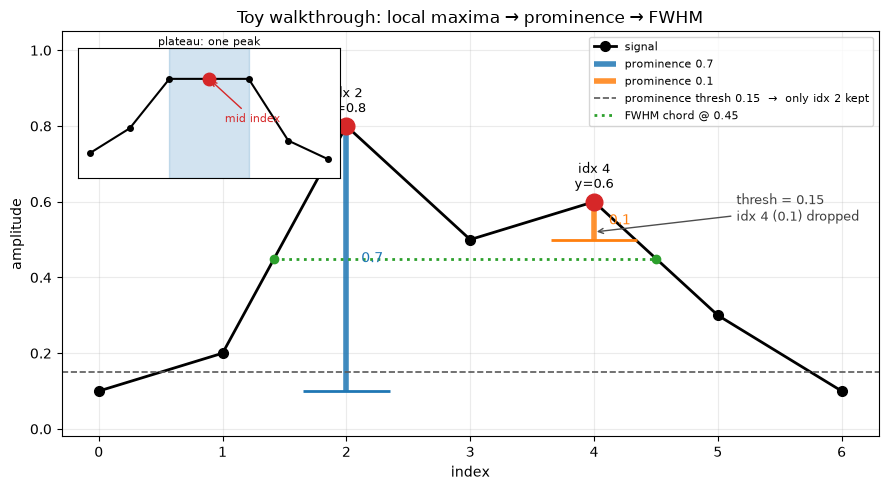

In [2]:
plt.style.use("default")

y = np.array([0.1, 0.2, 0.8, 0.5, 0.6, 0.3, 0.1], dtype=float)
x = np.arange(len(y))

peaks, _ = find_peaks(y)
proms, left_bases, right_bases = peak_prominences(y, peaks)
_, _, left_ips, right_ips = peak_widths(y, peaks, rel_height=0.5)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, y, "k-o", lw=2, ms=7, label="signal")

# peaks
ax.plot(peaks, y[peaks], "o", ms=12, color="C3", zorder=5)
for p, pr in zip(peaks, proms):
    ax.annotate(f"idx {p}\ny={y[p]:.1f}", xy=(p, y[p]),
                xytext=(0, 10), textcoords="offset points",
                ha="center", fontsize=9)

# prominence bars: peak → contour = peak - prominence
for p, pr, color, label in zip(
    peaks, proms, ["C0", "C1"], ["prominence 0.7", "prominence 0.1"]
):
    contour = y[p] - pr
    ax.vlines(p, contour, y[p], colors=color, lw=4, alpha=0.85, label=label)
    ax.hlines(contour, p - 0.35, p + 0.35, colors=color, lw=2)
    ax.text(p + 0.12, (y[p] + contour) / 2, f"{pr:.1f}", color=color, va="center")

# threshold: only peak 2 (prom 0.7) survives 0.15
ax.axhline(0.15, ls="--", color="0.35", lw=1.2,
           label="prominence thresh 0.15  →  only idx 2 kept")
# visual: 0.15 is a prominence cutoff, not a y-level.
# better as a note + hatch on the small bar:
ax.annotate(
    "thresh = 0.15\nidx 4 (0.1) dropped",
    xy=(4, y[4] - proms[1] + 0.02),
    xytext=(5.15, 0.55),
    arrowprops=dict(arrowstyle="->", color="0.3"),
    fontsize=9, color="0.25",
)

# FWHM-like chord on the big peak (rel_height=0.5 → y=0.45)
i_big = int(np.argmax(proms))
h_fwhm = y[peaks[i_big]] - 0.5 * proms[i_big]  # 0.45
ax.hlines(
    h_fwhm, left_ips[i_big], right_ips[i_big],
    colors="C2", lw=2, linestyles=":", label=f"FWHM chord @ {h_fwhm:.2f}",
)
ax.plot([left_ips[i_big], right_ips[i_big]], [h_fwhm, h_fwhm], "C2o", ms=6)

ax.set_xlabel("index")
ax.set_ylabel("amplitude")
ax.set_title("Toy walkthrough: local maxima → prominence → FWHM")
ax.set_ylim(-0.02, 1.05)
ax.set_xticks(x)
ax.legend(loc="upper right", fontsize=8)
ax.grid(True, alpha=0.25)

# inset: plateau → report mid index
axins = inset_axes(ax, width="32%", height="32%", loc="upper left", borderpad=1.2)
xp = np.array([0, 1, 2, 3, 4, 5, 6])
yp = np.array([0.2, 0.4, 0.8, 0.8, 0.8, 0.3, 0.15])
axins.plot(xp, yp, "k-o", ms=4)
axins.axvspan(2, 4, color="C0", alpha=0.2)
axins.plot(3, 0.8, "o", color="C3", ms=9, zorder=5)
axins.annotate("mid index", xy=(3, 0.8), xytext=(3.4, 0.45),
               arrowprops=dict(arrowstyle="->", color="C3"),
               fontsize=8, color="C3")
axins.set_title("plateau: one peak", fontsize=8, pad=2)
axins.set_xticks([])
axins.set_yticks([])
axins.set_ylim(0, 1.05)

plt.tight_layout()
plt.show()

/tmp/ipykernel_2237820/639411482.py:90: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


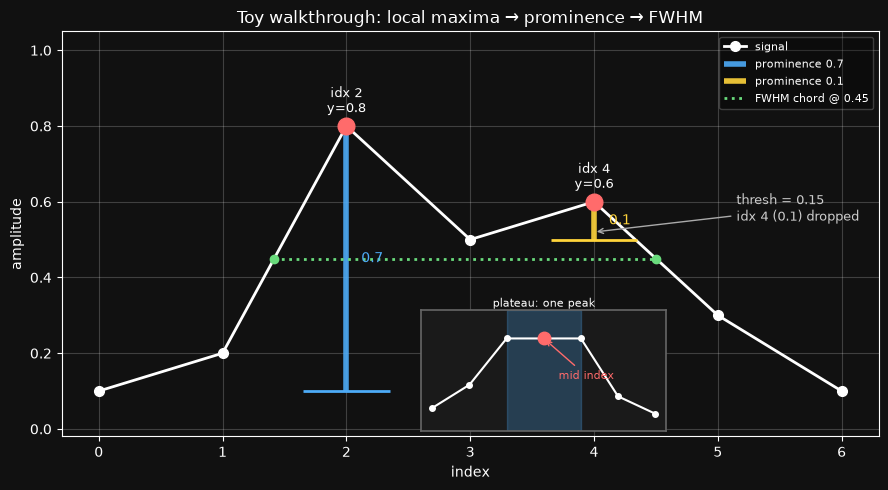

In [3]:
plt.style.use("dark_background")
y = np.array([0.1, 0.2, 0.8, 0.5, 0.6, 0.3, 0.1], dtype=float)
x = np.arange(len(y))
peaks, _ = find_peaks(y)
proms, left_bases, right_bases = peak_prominences(y, peaks)
_, _, left_ips, right_ips = peak_widths(y, peaks, rel_height=0.5)
fig, ax = plt.subplots(figsize=(9, 5), facecolor="#111111")
ax.set_facecolor("#111111")
fig.patch.set_facecolor("#111111")
ax.plot(x, y, color="white", marker="o", lw=2, ms=7, label="signal")
ax.plot(peaks, y[peaks], "o", ms=12, color="#ff6b6b", zorder=5)
for p, pr in zip(peaks, proms):
    ax.annotate(
        f"idx {p}\ny={y[p]:.1f}",
        xy=(p, y[p]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        color="white",
    )
for p, pr, color, label in zip(
    peaks, proms, ["#4dabf7", "#ffd43b"], ["prominence 0.7", "prominence 0.1"]
):
    contour = y[p] - pr
    ax.vlines(p, contour, y[p], colors=color, lw=4, alpha=0.9, label=label)
    ax.hlines(contour, p - 0.35, p + 0.35, colors=color, lw=2)
    ax.text(p + 0.12, (y[p] + contour) / 2, f"{pr:.1f}", color=color, va="center")
ax.annotate(
    "thresh = 0.15\nidx 4 (0.1) dropped",
    xy=(4, y[4] - proms[1] + 0.02),
    xytext=(5.15, 0.55),
    arrowprops=dict(arrowstyle="->", color="#aaaaaa"),
    fontsize=9,
    color="#cccccc",
)
i_big = int(np.argmax(proms))
h_fwhm = y[peaks[i_big]] - 0.5 * proms[i_big]
ax.hlines(
    h_fwhm,
    left_ips[i_big],
    right_ips[i_big],
    colors="#69db7c",
    lw=2,
    linestyles=":",
    label=f"FWHM chord @ {h_fwhm:.2f}",
)
ax.plot([left_ips[i_big], right_ips[i_big]], [h_fwhm, h_fwhm], "o", color="#69db7c", ms=6)
ax.set_xlabel("index")
ax.set_ylabel("amplitude")
ax.set_title("Toy walkthrough: local maxima → prominence → FWHM")
ax.set_ylim(-0.02, 1.05)
ax.set_xticks(x)
ax.legend(loc="upper right", fontsize=8, framealpha=0.25)
ax.grid(True, alpha=0.2)

axins = inset_axes(
    ax,
    width="30%",
    height="30%",
    loc="lower center",
    borderpad=0.1,          # inches from parent axes edge — try 2.5–3.5
    bbox_to_anchor=(0.09, 0.01, 1, 1),
    bbox_transform=ax.transAxes,
)
axins.set_facecolor("#1a1a1a")
for spine in axins.spines.values():
    spine.set_color("#888888")
    spine.set_linewidth(1.2)
    
xp = np.array([0, 1, 2, 3, 4, 5, 6])
yp = np.array([0.2, 0.4, 0.8, 0.8, 0.8, 0.3, 0.15])
axins.plot(xp, yp, color="white", marker="o", ms=4)
axins.axvspan(2, 4, color="#4dabf7", alpha=0.25)
axins.plot(3, 0.8, "o", color="#ff6b6b", ms=9, zorder=5)
axins.annotate(
    "mid index",
    xy=(3, 0.8),
    xytext=(3.4, 0.45),
    arrowprops=dict(arrowstyle="->", color="#ff6b6b"),
    fontsize=8,
    color="#ff6b6b",
)
axins.set_title("plateau: one peak", fontsize=8, pad=2, color="white")
axins.set_xticks([])
axins.set_yticks([])
axins.set_ylim(0, 1.05)
for spine in axins.spines.values():
    spine.set_color("#666666")
plt.tight_layout()
plt.show()

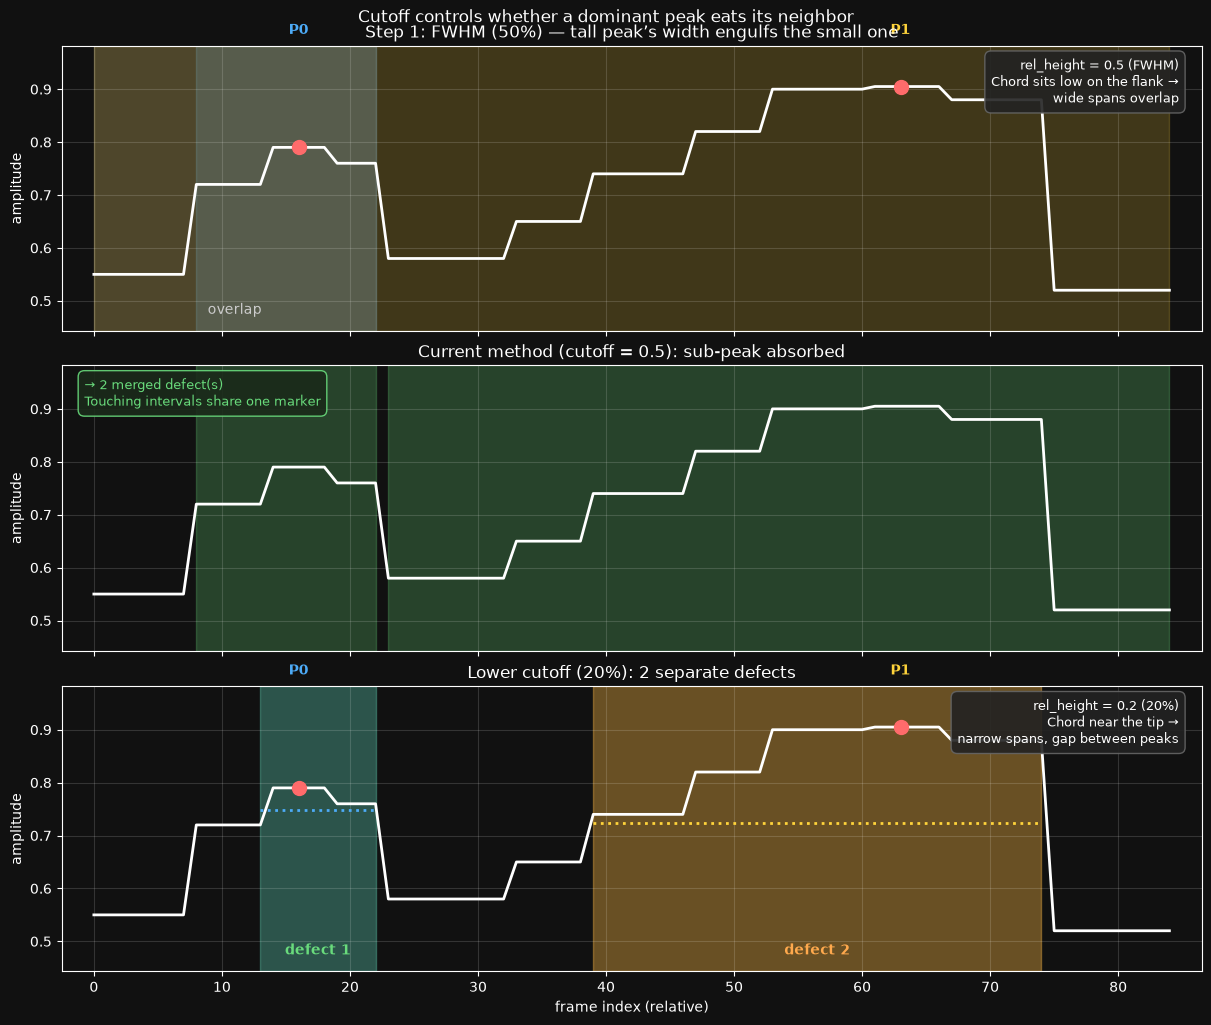

FWHM spans (raw): [(np.int64(8), np.int64(22)), (np.int64(0), np.int64(84))]
FWHM final:       [(1, np.int64(8), np.int64(22)), (1, np.int64(23), np.int64(84))]
20% spans (raw):  [(np.int64(13), np.int64(22)), (np.int64(39), np.int64(74))]
20% final:        [(1, np.int64(13), np.int64(22)), (2, np.int64(39), np.int64(74))]


In [4]:

def label_intervals(y, prominence=0.02, cutoff=0.5, pad=1):
    n = len(y)
    y_pad = np.pad(y, pad_width=pad, mode="constant", constant_values=0.0)
    peaks, _ = find_peaks(y_pad, prominence=prominence)
    if len(peaks) == 0:
        return peaks - pad, np.array([]), [], [], np.array([]), []
    proms, _, _ = peak_prominences(y_pad, peaks)
    _, _, left_ips, right_ips = peak_widths(y_pad, peaks, rel_height=cutoff)
    left = np.clip(np.round(left_ips).astype(int) - pad, 0, n - 1)
    right = np.clip(np.round(right_ips).astype(int) - pad, 0, n - 1)
    spans_raw = list(zip(left.copy(), right.copy()))
    for i in range(1, len(peaks)):
        if left[i] <= right[i - 1]:
            left[i] = right[i - 1] + 1
    marker = np.zeros(n, dtype=np.int32)
    defect_id, prev_end = 0, -2
    final_spans = []
    for s, e in zip(left, right):
        if s > prev_end + 1:
            defect_id += 1
        if s <= e:
            marker[s : e + 1] = defect_id
            final_spans.append((defect_id, s, e))
        prev_end = e
    return peaks - pad, proms, spans_raw, final_spans, marker, cutoff
steps = [
    (8, 0.55), (6, 0.72), (5, 0.79), (4, 0.76),
    (10, 0.58), (6, 0.65), (8, 0.74), (6, 0.82),
    (8, 0.90), (6, 0.905), (8, 0.88), (10, 0.52),
]
y = np.concatenate([np.full(c, v) for c, v in steps])
x = np.arange(len(y))
results = {
    "FWHM (50%)": label_intervals(y, cutoff=0.5),
    "20% cutoff": label_intervals(y, cutoff=0.2),
}
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True,
                         facecolor="#111111", constrained_layout=True)
colors = ["#4dabf7", "#ffd43b"]
for ax in axes:
    ax.set_facecolor("#111111")
    ax.margins(x=0.03, y=0.20)
# --- panel 1: FWHM raw widths ---
ax = axes[0]
ax.plot(x, y, color="white", lw=2)
peaks, proms, spans_raw, _, _, _ = results["FWHM (50%)"]
ax.plot(peaks, y[peaks], "o", color="#ff6b6b", ms=10, zorder=5)
for i, ((l, r), c) in enumerate(zip(spans_raw, colors)):
    ax.axvspan(l, r, color=c, alpha=0.20, zorder=0)
    ax.text(peaks[i], 1.03, f"P{i}", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", color=c, fontweight="bold")
if spans_raw[0][1] >= spans_raw[1][0]:
    ax.axvspan(spans_raw[1][0], spans_raw[0][1], color="white", alpha=0.08)
    ax.text((spans_raw[1][0] + spans_raw[0][1]) / 2, 0.06, "overlap",
            ha="center", transform=ax.get_xaxis_transform(), color="#ccc")
ax.text(0.98, 0.96,
        "rel_height = 0.5 (FWHM)\n"
        "Chord sits low on the flank →\nwide spans overlap",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.5", fc="#222", ec="#666", alpha=0.9))
ax.set_ylabel("amplitude")
ax.set_title("Step 1: FWHM (50%) — tall peak’s width engulfs the small one")
ax.grid(True, alpha=0.15)
# --- panel 2: FWHM merged result ---
ax = axes[1]
ax.plot(x, y, color="white", lw=2)
_, _, _, final_spans, marker, _ = results["FWHM (50%)"]
for did, s, e in final_spans:
    ax.axvspan(s, e, color="#69db7c", alpha=0.25)
ax.text(0.02, 0.96,
        f"→ {len(final_spans)} merged defect(s)\n"
        "Touching intervals share one marker",
        transform=ax.transAxes, ha="left", va="top", fontsize=9, color="#69db7c",
        bbox=dict(boxstyle="round,pad=0.5", fc="#1a2a1a", ec="#69db7c", alpha=0.9))
ax.set_ylabel("amplitude")
ax.set_title("Current method (cutoff = 0.5): sub-peak absorbed")
ax.grid(True, alpha=0.15)
# --- panel 3: 20% cutoff — two separate defects ---
ax = axes[2]
ax.plot(x, y, color="white", lw=2)
peaks2, proms2, spans_raw2, final_spans2, marker2, _ = results["20% cutoff"]
ax.plot(peaks2, y[peaks2], "o", color="#ff6b6b", ms=10, zorder=5)
defect_colors = ["#69db7c", "#ffa94d"]
for i, ((l, r), c) in enumerate(zip(spans_raw2, colors)):
    ax.axvspan(l, r, color=c, alpha=0.20, zorder=0)
    h = y[peaks2[i]] - 0.2 * proms2[i]
    ax.hlines(h, l, r, color=c, linestyles=":", lw=2)
    ax.text(peaks2[i], 1.03, f"P{i}", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", color=c, fontweight="bold")
for (did, s, e), dc in zip(final_spans2, defect_colors):
    ax.axvspan(s, e, color=dc, alpha=0.22, zorder=1)
    ax.text((s + e) / 2, 0.06, f"defect {did}",
            ha="center", transform=ax.get_xaxis_transform(), color=dc, fontweight="bold")
ax.text(0.98, 0.96,
        "rel_height = 0.2 (20%)\n"
        "Chord near the tip →\nnarrow spans, gap between peaks",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.5", fc="#222", ec="#666", alpha=0.9))
ax.set_xlabel("frame index (relative)")
ax.set_ylabel("amplitude")
ax.set_title(f"Lower cutoff (20%): {len(final_spans2)} separate defects")
ax.grid(True, alpha=0.15)
fig.suptitle("Cutoff controls whether a dominant peak eats its neighbor", fontsize=12, y=1.01)
plt.show()
print("FWHM spans (raw):", results["FWHM (50%)"][2])
print("FWHM final:      ", results["FWHM (50%)"][3])
print("20% spans (raw): ", results["20% cutoff"][2])
print("20% final:       ", results["20% cutoff"][3])

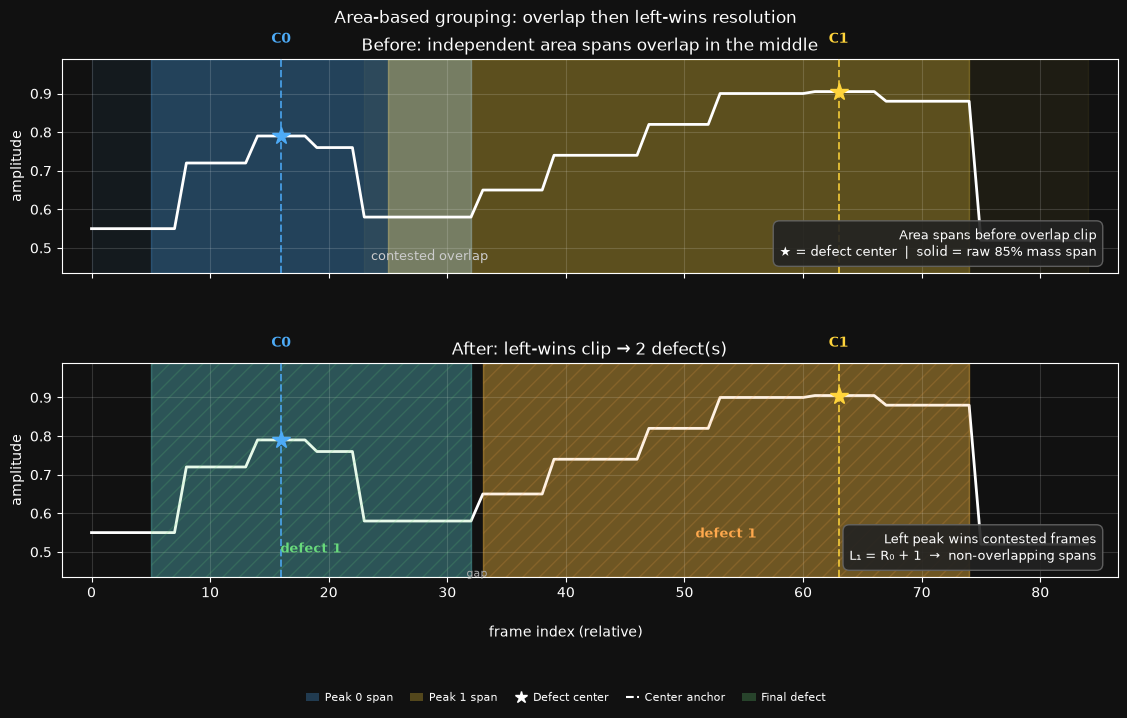

In [14]:
# ── area width helpers (inlined) ──────────────────────────────────────────────
def peak_valley_bounds(y, peak, baseline=0.0):
    lo = peak
    while lo > 0 and y[lo - 1] <= y[lo] and y[lo - 1] > baseline:
        lo -= 1
    hi = peak
    n = len(y)
    while hi < n - 1 and y[hi + 1] <= y[hi] and y[hi + 1] > baseline:
        hi += 1
    return lo, hi
def defect_center(y, peak, baseline=0.0):
    lo, hi = peak_valley_bounds(y, peak, baseline)
    seg = y[lo : hi + 1]
    ymax = seg.max()
    tol = max(1e-9, 1e-6 * ymax)
    at_max = np.flatnonzero(np.abs(seg - ymax) <= tol)
    if len(at_max) > 1:
        return lo + (at_max[0] + at_max[-1]) // 2
    return lo + int(np.argmax(seg))
def peak_area_bounds(y, peak, baseline=0.0, area_frac=0.85):
    ref = defect_center(y, peak, baseline)
    lo, hi = peak_valley_bounds(y, ref, baseline)
    seg = np.maximum(y[lo : hi + 1] - baseline, 0.0)
    total = seg.sum()
    if total == 0:
        return ref, ref
    target = area_frac * total
    r = ref - lo
    left = right = r
    captured = seg[r]
    while captured < target and (left > 0 or right < len(seg) - 1):
        mass_left = seg[left - 1] if left > 0 else -1.0
        mass_right = seg[right + 1] if right < len(seg) - 1 else -1.0
        if mass_right >= mass_left:
            right += 1
            captured += seg[right]
        else:
            left -= 1
            captured += seg[left]
    return lo + left, lo + right
def resolve_overlaps_left_wins(left, right):
    left, right = left.copy(), right.copy()
    for i in range(1, len(left)):
        if left[i] <= right[i - 1]:
            left[i] = right[i - 1] + 1
    return left, right
def _assign_markers(left, right, n):
    defect_id, prev_end = 0, -2
    final = []
    for s, e in zip(left, right):
        if s > prev_end + 1:
            defect_id += 1
        if s <= e:
            final.append((defect_id, s, e))
        prev_end = e
    return final
def label_area(y, prominence=0.02, area_frac=0.85, pad=1):
    n = len(y)
    y_pad = np.pad(y, pad_width=pad, mode="constant", constant_values=0.0)
    peaks, _ = find_peaks(y_pad, prominence=prominence)
    if len(peaks) == 0:
        return None
    centers, valleys, spans_raw = [], [], []
    left, right = [], []
    for p in peaks:
        ref = defect_center(y_pad, int(p), 0.0)
        vlo, vhi = peak_valley_bounds(y_pad, ref, 0.0)
        l, r = peak_area_bounds(y_pad, int(p), 0.0, area_frac)
        centers.append(ref - pad)
        valleys.append((vlo - pad, vhi - pad))
        spans_raw.append((l - pad, r - pad))
        left.append(l - pad)
        right.append(r - pad)
    left = np.array(left)
    right = np.array(right)
    left_clip, right_clip = resolve_overlaps_left_wins(left, right)
    valid = left_clip <= right_clip
    return dict(
        peaks=peaks[valid] - pad,
        centers=[centers[i] for i in np.where(valid)[0]],
        valleys=[valleys[i] for i in np.where(valid)[0]],
        spans_raw=[spans_raw[i] for i in np.where(valid)[0]],
        spans_clip=list(zip(left_clip[valid], right_clip[valid])),
        final=_assign_markers(left_clip[valid], right_clip[valid], n),
    )
# ── toy signal ───────────────────────────────────────────────────────────────
plt.style.use("dark_background")
steps = [
    (8, 0.55), (6, 0.72), (5, 0.79), (4, 0.76),
    (10, 0.58), (6, 0.65), (8, 0.74), (6, 0.82),
    (8, 0.90), (6, 0.905), (8, 0.88), (10, 0.52),
]
y = np.concatenate([np.full(c, v) for c, v in steps])
x = np.arange(len(y))
ar = label_area(y, area_frac=0.85)
colors = ["#4dabf7", "#ffd43b"]
defect_colors = ["#69db7c", "#ffa94d"]
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                         facecolor="#111111", constrained_layout=False)
fig.subplots_adjust(left=0.08, right=0.96, top=0.90, bottom=0.16, hspace=0.42)
for ax in axes:
    ax.set_facecolor("#111111")
    ax.margins(x=0.03, y=0.22)
    ax.grid(True, alpha=0.15)
    ax.plot(x, y, color="white", lw=2)
# ── panel 1: overlap (raw spans) ─────────────────────────────────────────────
ax = axes[0]
for i, p in enumerate(ar["peaks"]):
    c = colors[i]
    ref = ar["centers"][i]
    vlo, vhi = ar["valleys"][i]
    l, r = ar["spans_raw"][i]
    ax.axvspan(vlo, vhi, color=c, alpha=0.06, zorder=0)
    ax.axvspan(l, r, color=c, alpha=0.28, zorder=1)
    ax.axvline(ref, color=c, ls="--", lw=1.4, alpha=0.8, zorder=3)
    ax.plot(ref, y[ref], "*", color=c, ms=13, zorder=5)
    ax.text(ref, 1.06, f"C{i}", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", color=c, fontweight="bold")
if ar["spans_raw"][0][1] >= ar["spans_raw"][1][0]:
    ov_lo, ov_hi = ar["spans_raw"][1][0], ar["spans_raw"][0][1]
    ax.axvspan(ov_lo, ov_hi, color="white", alpha=0.10, zorder=2)
    ax.text((ov_lo + ov_hi) / 2, 0.06, "contested overlap",
            ha="center", transform=ax.get_xaxis_transform(), color="#ccc", fontsize=9)
# panel 1 callout — bottom right
ax.text(
    0.98, 0.06,
    "Area spans before overlap clip\n"
    "★ = defect center  |  solid = raw 85% mass span",
    transform=ax.transAxes,
    ha="right", va="bottom", fontsize=9,
    bbox=dict(boxstyle="round,pad=0.5", fc="#222", ec="#666", alpha=0.9),
)
ax.set_ylabel("amplitude")
ax.set_title("Before: independent area spans overlap in the middle")
# ── panel 2: resolution (left wins, post-clip) ───────────────────────────────
ax = axes[1]
label_ys = [0.10, 0.17]
for i, p in enumerate(ar["peaks"]):
    c = colors[i]
    ref = ar["centers"][i]
    l, r = ar["spans_clip"][i]
    ax.axvspan(l, r, color=c, alpha=0.28, zorder=1)
    ax.axvline(ref, color=c, ls="--", lw=1.4, alpha=0.8, zorder=3)
    ax.plot(ref, y[ref], "*", color=c, ms=13, zorder=5)
    ax.text(ref, 1.06, f"C{i}", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", color=c, fontweight="bold")
for j, ((did, s, e), dc) in enumerate(zip(ar["final"], defect_colors)):
    ax.axvspan(s, e, color=dc, alpha=0.16, zorder=2, hatch="//")
    ax.text((s + e) / 2, label_ys[j % 2], f"defect {did}",
            ha="center", va="bottom", transform=ax.get_xaxis_transform(),
            color=dc, fontweight="bold", fontsize=9, clip_on=False)
if ar["spans_clip"][0][1] < ar["spans_clip"][1][0]:
    gap_mid = (ar["spans_clip"][0][1] + ar["spans_clip"][1][0]) / 2
    ax.text(gap_mid, 0.04, "gap", ha="center", va="top",
            transform=ax.get_xaxis_transform(), color="#aaa", fontsize=8)
else:
    touch = (ar["spans_clip"][0][1] + ar["spans_clip"][1][0]) / 2
    ax.text(touch, 0.04, "touch → merge", ha="center", va="top",
            transform=ax.get_xaxis_transform(), color="#aaa", fontsize=8)
# panel 2 callout — bottom right
ax.text(
    0.98, 0.06,
    "Left peak wins contested frames\n"
    "L₁ = R₀ + 1  →  non-overlapping spans",
    transform=ax.transAxes,
    ha="right", va="bottom", fontsize=9,
    bbox=dict(boxstyle="round,pad=0.5", fc="#222", ec="#666", alpha=0.9),
)
ax.set_ylabel("amplitude")
ax.set_title(f"After: left-wins clip → {len(ar['final'])} defect(s)")
fig.supxlabel("frame index (relative)", y=0.07, fontsize=10)
fig.suptitle("Area-based grouping: overlap then left-wins resolution", fontsize=12, y=0.97)
legend_elems = [
    Patch(facecolor="#4dabf7", alpha=0.28, label="Peak 0 span"),
    Patch(facecolor="#ffd43b", alpha=0.28, label="Peak 1 span"),
    plt.Line2D([0], [0], marker="*", color="w", ls="", ms=9, label="Defect center"),
    plt.Line2D([0], [0], color="w", ls="--", lw=1.5, label="Center anchor"),
    Patch(facecolor="#69db7c", alpha=0.25, label="Final defect"),
]
fig.legend(handles=legend_elems, loc="upper center",
           bbox_to_anchor=(0.5, 0.01), ncol=5, frameon=False, fontsize=8,
           handlelength=1.2, handletextpad=0.5, columnspacing=1.5)
plt.show()

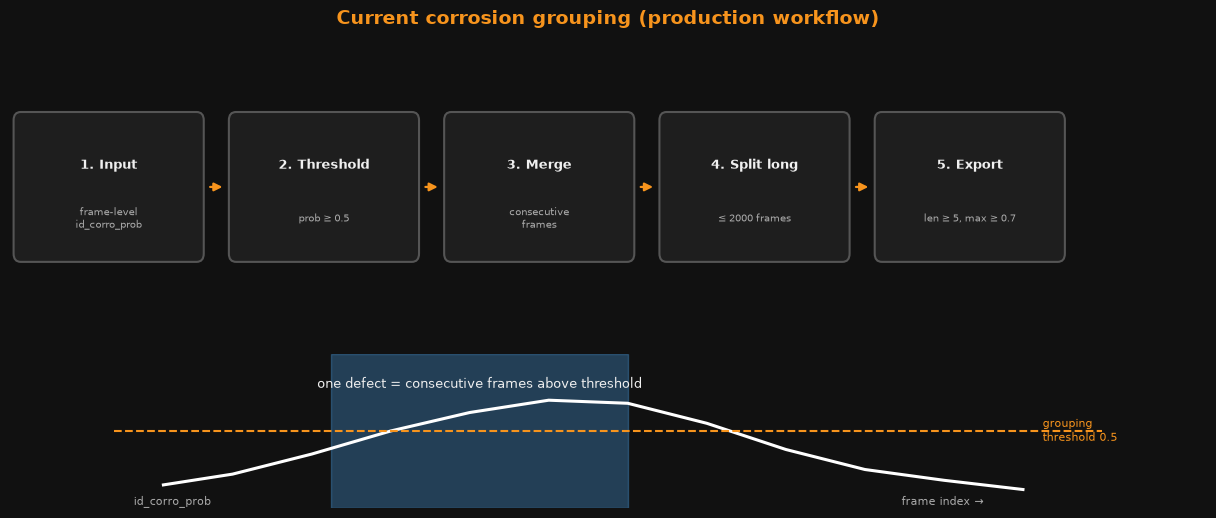

In [16]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

BG        = "#111111"
BOX       = "#1e1e1e"
BORDER    = "#555555"
DV_ORANGE = "#F7941D"
BLUE      = "#4dabf7"
TEXT      = "#f0f0f0"
MUTED     = "#aaaaaa"

fig = plt.figure(figsize=(13, 5.5), facecolor=BG)
ax_flow = fig.add_axes([0.04, 0.42, 0.92, 0.50])   # top: pipeline only
ax_demo = fig.add_axes([0.12, 0.08, 0.76, 0.28])   # bottom: signal cartoon
for ax in (ax_flow, ax_demo):
    ax.set_facecolor(BG)
    ax.axis("off")

fig.text(0.5, 0.96, "Current corrosion grouping (production workflow)",
         ha="center", fontsize=14, fontweight="bold", color=DV_ORANGE)

# ── top: pipeline ────────────────────────────────────────────────────────────
ax_flow.set_xlim(0, 10)
ax_flow.set_ylim(0, 2)

def box(ax, x, title, subtitle):
    w, h = 1.55, 1.05
    y = 0.45
    ax.add_patch(FancyBboxPatch(
        (x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.06",
        facecolor=BOX, edgecolor=BORDER, linewidth=1.5,
    ))
    ax.text(x + w/2, y + h*0.65, title, ha="center", va="center",
            fontsize=9.5, fontweight="bold", color=TEXT)
    ax.text(x + w/2, y + h*0.28, subtitle, ha="center", va="center",
            fontsize=7.5, color=MUTED)

steps = [
    (0.05,  "1. Input",          "frame-level\nid_corro_prob"),
    (1.85,  "2. Threshold",     "prob ≥ 0.5"),
    (3.65,  "3. Merge",         "consecutive\nframes"),
    (5.45,  "4. Split long",    "≤ 2000 frames"),
    (7.25,  "5. Export",        "len ≥ 5, max ≥ 0.7"),
]
for x, t, s in steps:
    box(ax_flow, x, t, s)

for i in range(len(steps) - 1):
    x1 = steps[i][0] + 1.55 + 0.05
    x2 = steps[i+1][0] - 0.05
    ax_flow.add_patch(FancyArrowPatch(
        (x1, 0.975), (x2, 0.975), arrowstyle="-|>", mutation_scale=12,
        lw=1.6, color=DV_ORANGE, transform=ax_flow.transData,
    ))

# ── bottom: threshold cartoon (own axes, 0–1 coords) ───────────────────────
ax_demo.set_xlim(0, 1)
ax_demo.set_ylim(0, 1)

xs = [0.05, 0.12, 0.20, 0.28, 0.36, 0.44, 0.52, 0.60, 0.68, 0.76, 0.84, 0.92]
ys = [0.15, 0.22, 0.35, 0.50, 0.62, 0.70, 0.68, 0.55, 0.38, 0.25, 0.18, 0.12]
ax_demo.plot(xs, ys, color="white", lw=2.2)

ax_demo.axhline(0.50, color=DV_ORANGE, ls="--", lw=1.5)
ax_demo.text(0.94, 0.50, "grouping\nthreshold 0.5", va="center", ha="left",
             fontsize=8, color=DV_ORANGE)

ax_demo.axvspan(0.22, 0.52, color=BLUE, alpha=0.30)
ax_demo.text(0.37, 0.78, "one defect = consecutive frames above threshold",
             ha="center", fontsize=9, color=TEXT)

ax_demo.text(0.02, 0.02, "id_corro_prob", fontsize=8, color=MUTED)
ax_demo.text(0.88, 0.02, "frame index →", fontsize=8, color=MUTED, ha="right")

fig.savefig("current_production_grouping_intro.png", dpi=200,
            facecolor=BG, bbox_inches="tight")
plt.show()